In [19]:
# ==============================================================================
# END-TO-END TIME SERIES ANALYSIS & FORECASTING: MONTHLY SALES (2021-2026)
# Covers: Preparation, Cleaning, Outlier Audit, EDA, Decomposition,
#         Chronological Split, Baselines, Holt-Winters, SARIMA & 2026 Forecast
# ==============================================================================

import os 
import warnings 
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing 
from statsmodels.tsa.statespace.sarimax import SARIMAX 

warnings.filterwarnings("ignore")
np.random.seed(42)

In [26]:
# ------------------------------------------------------------------------------
# 1. LOAD, PREPARE & CLEAN TIME SERIES DATA
# ------------------------------------------------------------------------------
file_path = "montly.sales_2.csv" if os.path.exists("montly.sales_2.csv") else "montly.sales.csv"
df = pd.read_csv(file_path)

# Step 1: Parse dates | Step 2: Sort chronologically | Step 3: Set DatetimeIndex | Step 4: Enforce 'MS' frequency
df["month"] = pd.to_datetime(df["month"])
df = df.sort_values("month").set_index("month").asfreq("MS")

# Step 5: Verify Data Quality & Completeness
full_range = pd.date_range(df.index.min(), df.index.max(), freq="MS")
print("=== 1. DATA QUALITY AUDIT ===")
print(f"Total Observations : {len(df)} months ({df.index.min().date()} to {df.index.max().date()})")
print(f"Missing Values     : {df['sales_million_rp'].isna().sum()}")
print(f"Duplicate Dates    : {df.index.duplicated().sum()}")
print(f"Missing Months     : {len(full_range.difference(df.index))}")

# Classical Multiplicative Decomposition for Trend, Seasonal Index & Outlier Z-Score Audit
decomp = seasonal_decompose(df["sales_million_rp"], model="multiplicative", period=12)
df["trend"] = decomp.trend
df["seasonal_index"] = decomp.seasonal
df["residual"] = decomp.resid

resid_valid = df["residual"].dropna()
df["resid_zscore"] = (df["residual"] - resid_valid.mean()) / resid_valid.std()

print("\n=== 2. IRREGULAR OUTLIER AUDIT (TOP RESIDUAL Z-SCORES) ===")
outliers = df.reindex(df["resid_zscore"].abs().dropna().sort_values(ascending=False).index).head(10)
print(outliers[["sales_million_rp", "seasonal_index", "residual", "resid_zscore"]].round(3))

=== 1. DATA QUALITY AUDIT ===
Total Observations : 60 months (2021-01-01 to 2025-12-01)
Missing Values     : 0
Duplicate Dates    : 0
Missing Months     : 0

=== 2. IRREGULAR OUTLIER AUDIT (TOP RESIDUAL Z-SCORES) ===
            sales_million_rp  seasonal_index  residual  resid_zscore
month                                                               
2023-11-01             363.4           1.134     1.081         3.693
2022-02-01             229.9           0.926     1.041         1.868
2024-11-01             353.5           1.134     0.963        -1.741
2024-07-01             293.6           0.971     0.966        -1.586
2024-03-01             279.6           0.948     0.966        -1.568
2024-02-01             271.2           0.926     0.969        -1.441
2022-04-01             230.6           0.976     0.970        -1.401
2025-05-01             324.9           0.994     0.970        -1.401
2023-07-01             286.6           0.971     1.027         1.234
2022-06-01             2


=== 3. YEARLY SUMMARY STATISTICS (MILLION RP) ===
      count    mean  median    std    min    max     sum  yoy_growth_%
Year                                                                  
2021     12  217.52  213.35  24.57  184.1  274.7  2610.2           NaN
2022     12  250.12  246.55  23.12  229.9  302.6  3001.5         14.99
2023     12  285.77  276.65  34.51  246.6  363.4  3429.2         14.25
2024     12  311.37  307.30  29.02  271.2  376.4  3736.4          8.96
2025     12  341.32  331.25  30.51  306.9  417.8  4095.8          9.62

=== 4. MONTHLY SEASONAL PROFILE & MULTIPLICATIVE INDICES ===
                   mean  median     std    min    max  seasonal_idx
Month_Num Month                                                    
1         Jan    281.60   277.4  52.058  218.4  351.0         1.050
2         Feb    247.74   246.6  45.880  184.1  306.9         0.926
3         Mar    259.02   261.3  43.404  204.9  317.6         0.948
4         Apr    270.26   270.4  48.901  215.0  33

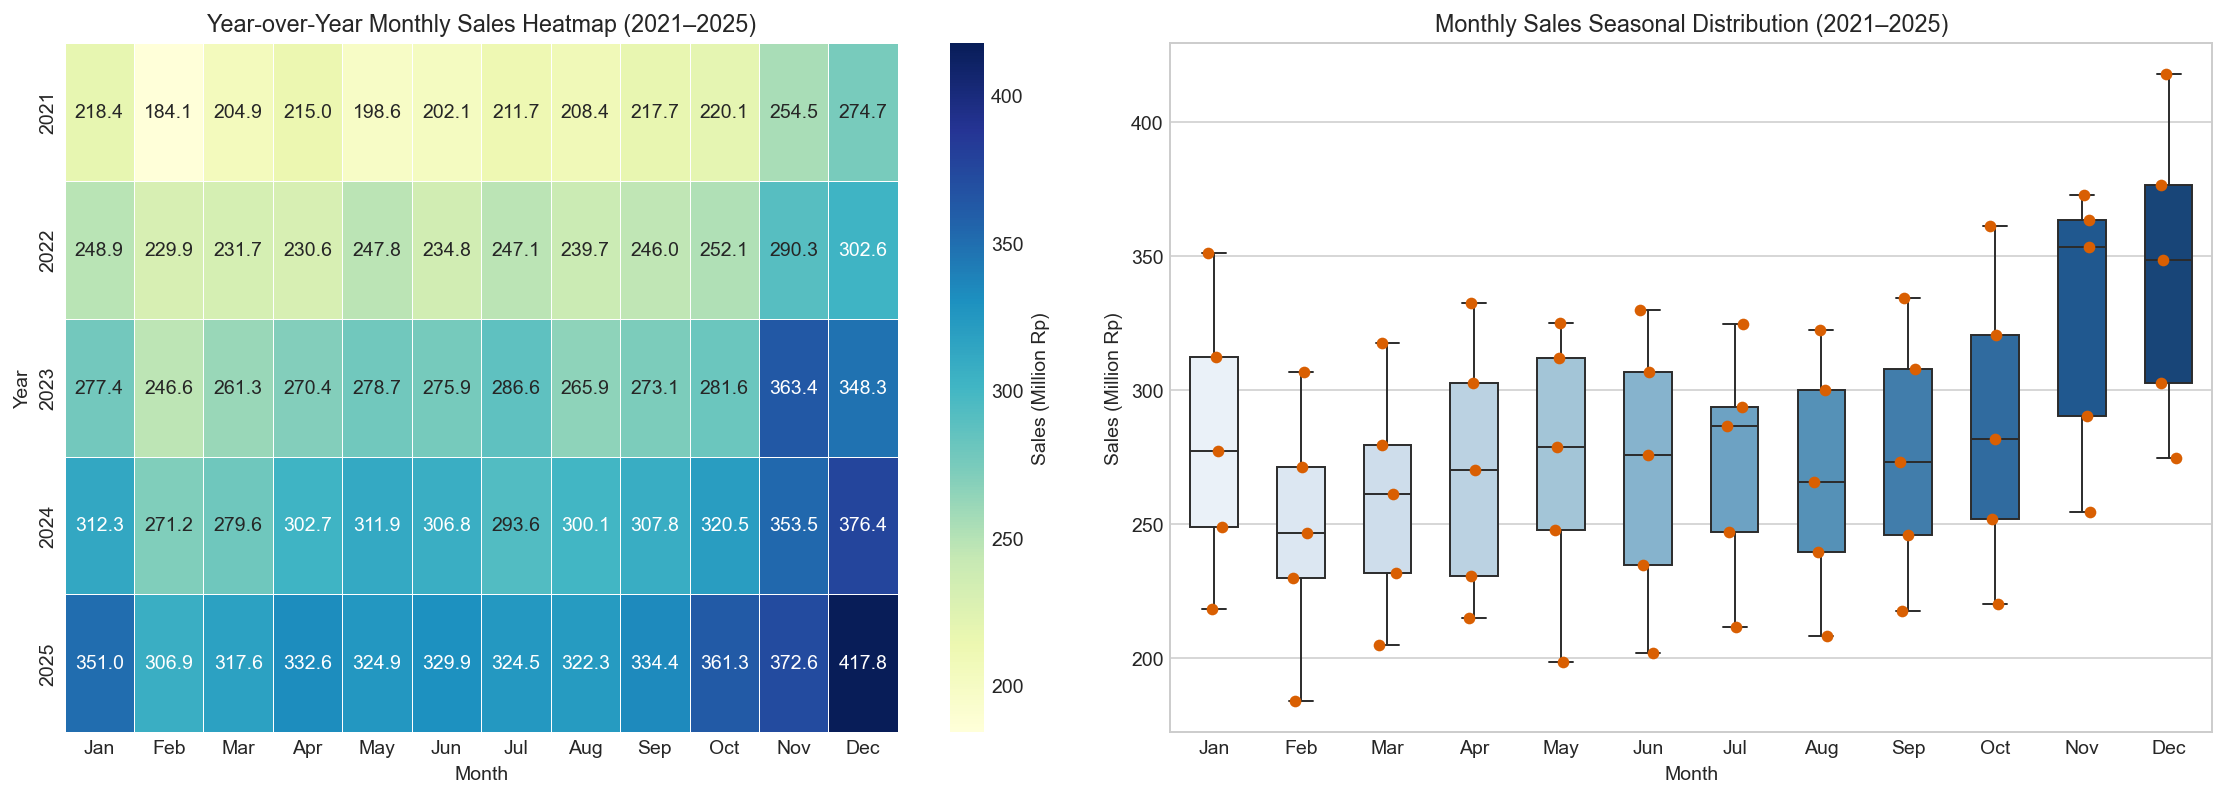

In [27]:
# ------------------------------------------------------------------------------
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# ------------------------------------------------------------------------------
df_eda = df.copy()
df_eda["Year"] = df_eda.index.year
df_eda["Month_Num"] = df_eda.index.month
df_eda["Month"] = df_eda.index.strftime("%b")

print("\n=== 3. YEARLY SUMMARY STATISTICS (MILLION RP) ===")
yearly_stats = df_eda.groupby("Year")["sales_million_rp"].agg(
    ["count", "mean", "median", "std", "min", "max", "sum"]
).round(2)
yearly_stats["yoy_growth_%"] = (yearly_stats["sum"].pct_change() * 100).round(2)
print(yearly_stats.to_string())

print("\n=== 4. MONTHLY SEASONAL PROFILE & MULTIPLICATIVE INDICES ===")
monthly_stats = df_eda.groupby(["Month_Num", "Month"]).agg(
    mean=("sales_million_rp", "mean"),
    median=("sales_million_rp", "median"),
    std=("sales_million_rp", "std"),
    min=("sales_million_rp", "min"),
    max=("sales_million_rp", "max"),
    seasonal_idx=("seasonal_index", "first"),
).round(3)
print(monthly_stats.to_string())

# Visualize Year-by-Month Heatmap & Seasonal Boxplot
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
pivot_sales = df_eda.pivot(index="Year", columns="Month", values="sales_million_rp")[month_order]

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), dpi=140)
sns.heatmap(pivot_sales, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5, ax=axes[0],
            cbar_kws={"label": "Sales (Million Rp)"})
axes[0].set(title="Year-over-Year Monthly Sales Heatmap (2021–2025)", xlabel="Month", ylabel="Year")

sns.boxplot(data=df_eda, x="Month", y="sales_million_rp", order=month_order, palette="Blues", width=0.55, ax=axes[1])
sns.stripplot(data=df_eda, x="Month", y="sales_million_rp", order=month_order, color="#d95f02", size=6, ax=axes[1])
axes[1].set(title="Monthly Sales Seasonal Distribution (2021–2025)", xlabel="Month", ylabel="Sales (Million Rp)")
plt.tight_layout()
plt.show()

In [28]:
# ------------------------------------------------------------------------------
# 3. CHRONOLOGICAL TRAIN-TEST SPLIT (h = 12 MONTHS)
# ------------------------------------------------------------------------------
h = 12
train = df["sales_million_rp"].iloc[:-h]  # Jan 2021 - Dec 2024 (48 months)
test = df["sales_million_rp"].iloc[-h:]   # Jan 2025 - Dec 2025 (12 months)
y_test = test

# Create Promo-Cleaned Training Series (interpolating Nov 2023 +3.69 sigma spike)
train_cleaned = train.copy()
train_cleaned.loc["2023-11-01"] = (train.loc["2022-11-01"] + train.loc["2024-11-01"]) / 2

In [29]:
# ------------------------------------------------------------------------------
# 4. BUILD BASELINE & ADVANCED FORECASTING MODELS
# ------------------------------------------------------------------------------
naive_pred = pd.Series(train.iloc[-1], index=test.index)
ma3_pred = pd.Series(train.iloc[-3:].mean(), index=test.index)
snaive_pred = pd.Series(train.iloc[-12:].values, index=test.index)

hw_add_pred = ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=12
).fit().forecast(h)
hw_add_pred.index = test.index

hw_mul_pred = ExponentialSmoothing(
    train, trend="add", seasonal="mul", seasonal_periods=12
).fit().forecast(h)
hw_mul_pred.index = test.index

hw_clean_pred = ExponentialSmoothing(
    train_cleaned, trend="add", seasonal="mul", seasonal_periods=12
).fit().forecast(h)
hw_clean_pred.index = test.index

sarima_pred = SARIMAX(
    train, order=(1, 1, 0), seasonal_order=(0, 1, 1, 12), trend="c"
).fit(disp=False).forecast(h)
sarima_pred.index = test.index

In [30]:
# ------------------------------------------------------------------------------
# 5. EVALUATE TEST SET PERFORMANCE (MAE, RMSE, MAPE)
# ------------------------------------------------------------------------------
def evaluate(name, y_true, predictions):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    mape = np.mean(np.abs((y_true - predictions) / y_true)) * 100
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "MAPE (%)": round(mape, 2)}

results = pd.DataFrame([
    evaluate("Holt-Winters Mul (Promo-Cleaned)", y_test, hw_clean_pred),
    evaluate("Holt-Winters Mul (Standard)", y_test, hw_mul_pred),
    evaluate("Holt-Winters Add (Standard)", y_test, hw_add_pred),
    evaluate("SARIMA(1,1,0)(0,1,1,12)", y_test, sarima_pred),
    evaluate("Moving Average (k=3)", y_test, ma3_pred),
    evaluate("Seasonal Naive", y_test, snaive_pred),
    evaluate("Naive Baseline", y_test, naive_pred),
]).sort_values("MAE")

print("\n=== 5. TEST SET MODEL EVALUATION (JAN–DEC 2025) ===")
print(results.to_string(index=False))


=== 5. TEST SET MODEL EVALUATION (JAN–DEC 2025) ===
                           Model   MAE  RMSE  MAPE (%)
Holt-Winters Mul (Promo-Cleaned)  6.42  8.89      1.86
     Holt-Winters Mul (Standard)  7.66 11.94      2.20
     Holt-Winters Add (Standard)  9.82 11.27      2.83
         SARIMA(1,1,0)(0,1,1,12) 10.32 11.72      2.99
            Moving Average (k=3) 25.84 30.51      7.53
                  Seasonal Naive 29.95 31.24      8.78
                  Naive Baseline 41.98 45.65     12.66


In [31]:
# ------------------------------------------------------------------------------
# 6. REFIT ON ALL 60 MONTHS & FORECAST NEXT 12 MONTHS (JAN–DEC 2026)
# ------------------------------------------------------------------------------
s_full = df["sales_million_rp"]
s_full_cleaned = s_full.copy()
s_full_cleaned.loc["2023-11-01"] = (s_full.loc["2022-11-01"] + s_full.loc["2024-11-01"]) / 2

f2026_mul_std = ExponentialSmoothing(
    s_full, trend="add", seasonal="mul", seasonal_periods=12
).fit().forecast(12)

f2026_mul_clean = ExponentialSmoothing(
    s_full_cleaned, trend="add", seasonal="mul", seasonal_periods=12
).fit().forecast(12)

forecast_2026_df = pd.DataFrame({
    "Month": f2026_mul_std.index.strftime("%b %Y"),
    "2025_Actual": s_full.iloc[-12:].values.round(1),
    "2026_HW_Mul_Std": f2026_mul_std.values.round(1),
    "2026_HW_Mul_PromoCleaned": f2026_mul_clean.values.round(1),
    "YoY_Diff_Std": (f2026_mul_std.values - s_full.iloc[-12:].values).round(1),
})

print("\n=== 6. 2026 MONTHLY SALES FORECAST (MILLION RP) ===")
print(forecast_2026_df.to_string(index=False))
print(f"\nProjected 2026 Annual Revenue (Standard HW Mul)     : {f2026_mul_std.sum():.1f} million Rp")
print(f"Projected 2026 Annual Revenue (Promo-Cleaned HW Mul): {f2026_mul_clean.sum():.1f} million Rp")


=== 6. 2026 MONTHLY SALES FORECAST (MILLION RP) ===
   Month  2025_Actual  2026_HW_Mul_Std  2026_HW_Mul_PromoCleaned  YoY_Diff_Std
Jan 2026        351.0            379.4                     379.7          28.4
Feb 2026        306.9            333.0                     333.2          26.1
Mar 2026        317.6            346.6                     346.8          29.0
Apr 2026        332.6            361.5                     361.7          28.9
May 2026        324.9            363.8                     364.0          38.9
Jun 2026        329.9            360.1                     360.3          30.2
Jul 2026        324.5            361.4                     361.6          36.9
Aug 2026        322.3            354.1                     354.3          31.8
Sep 2026        334.4            364.6                     364.8          30.2
Oct 2026        361.3            380.0                     380.3          18.7
Nov 2026        372.6            429.1                     418.6          56.5

**DATA VISUALIZATION**

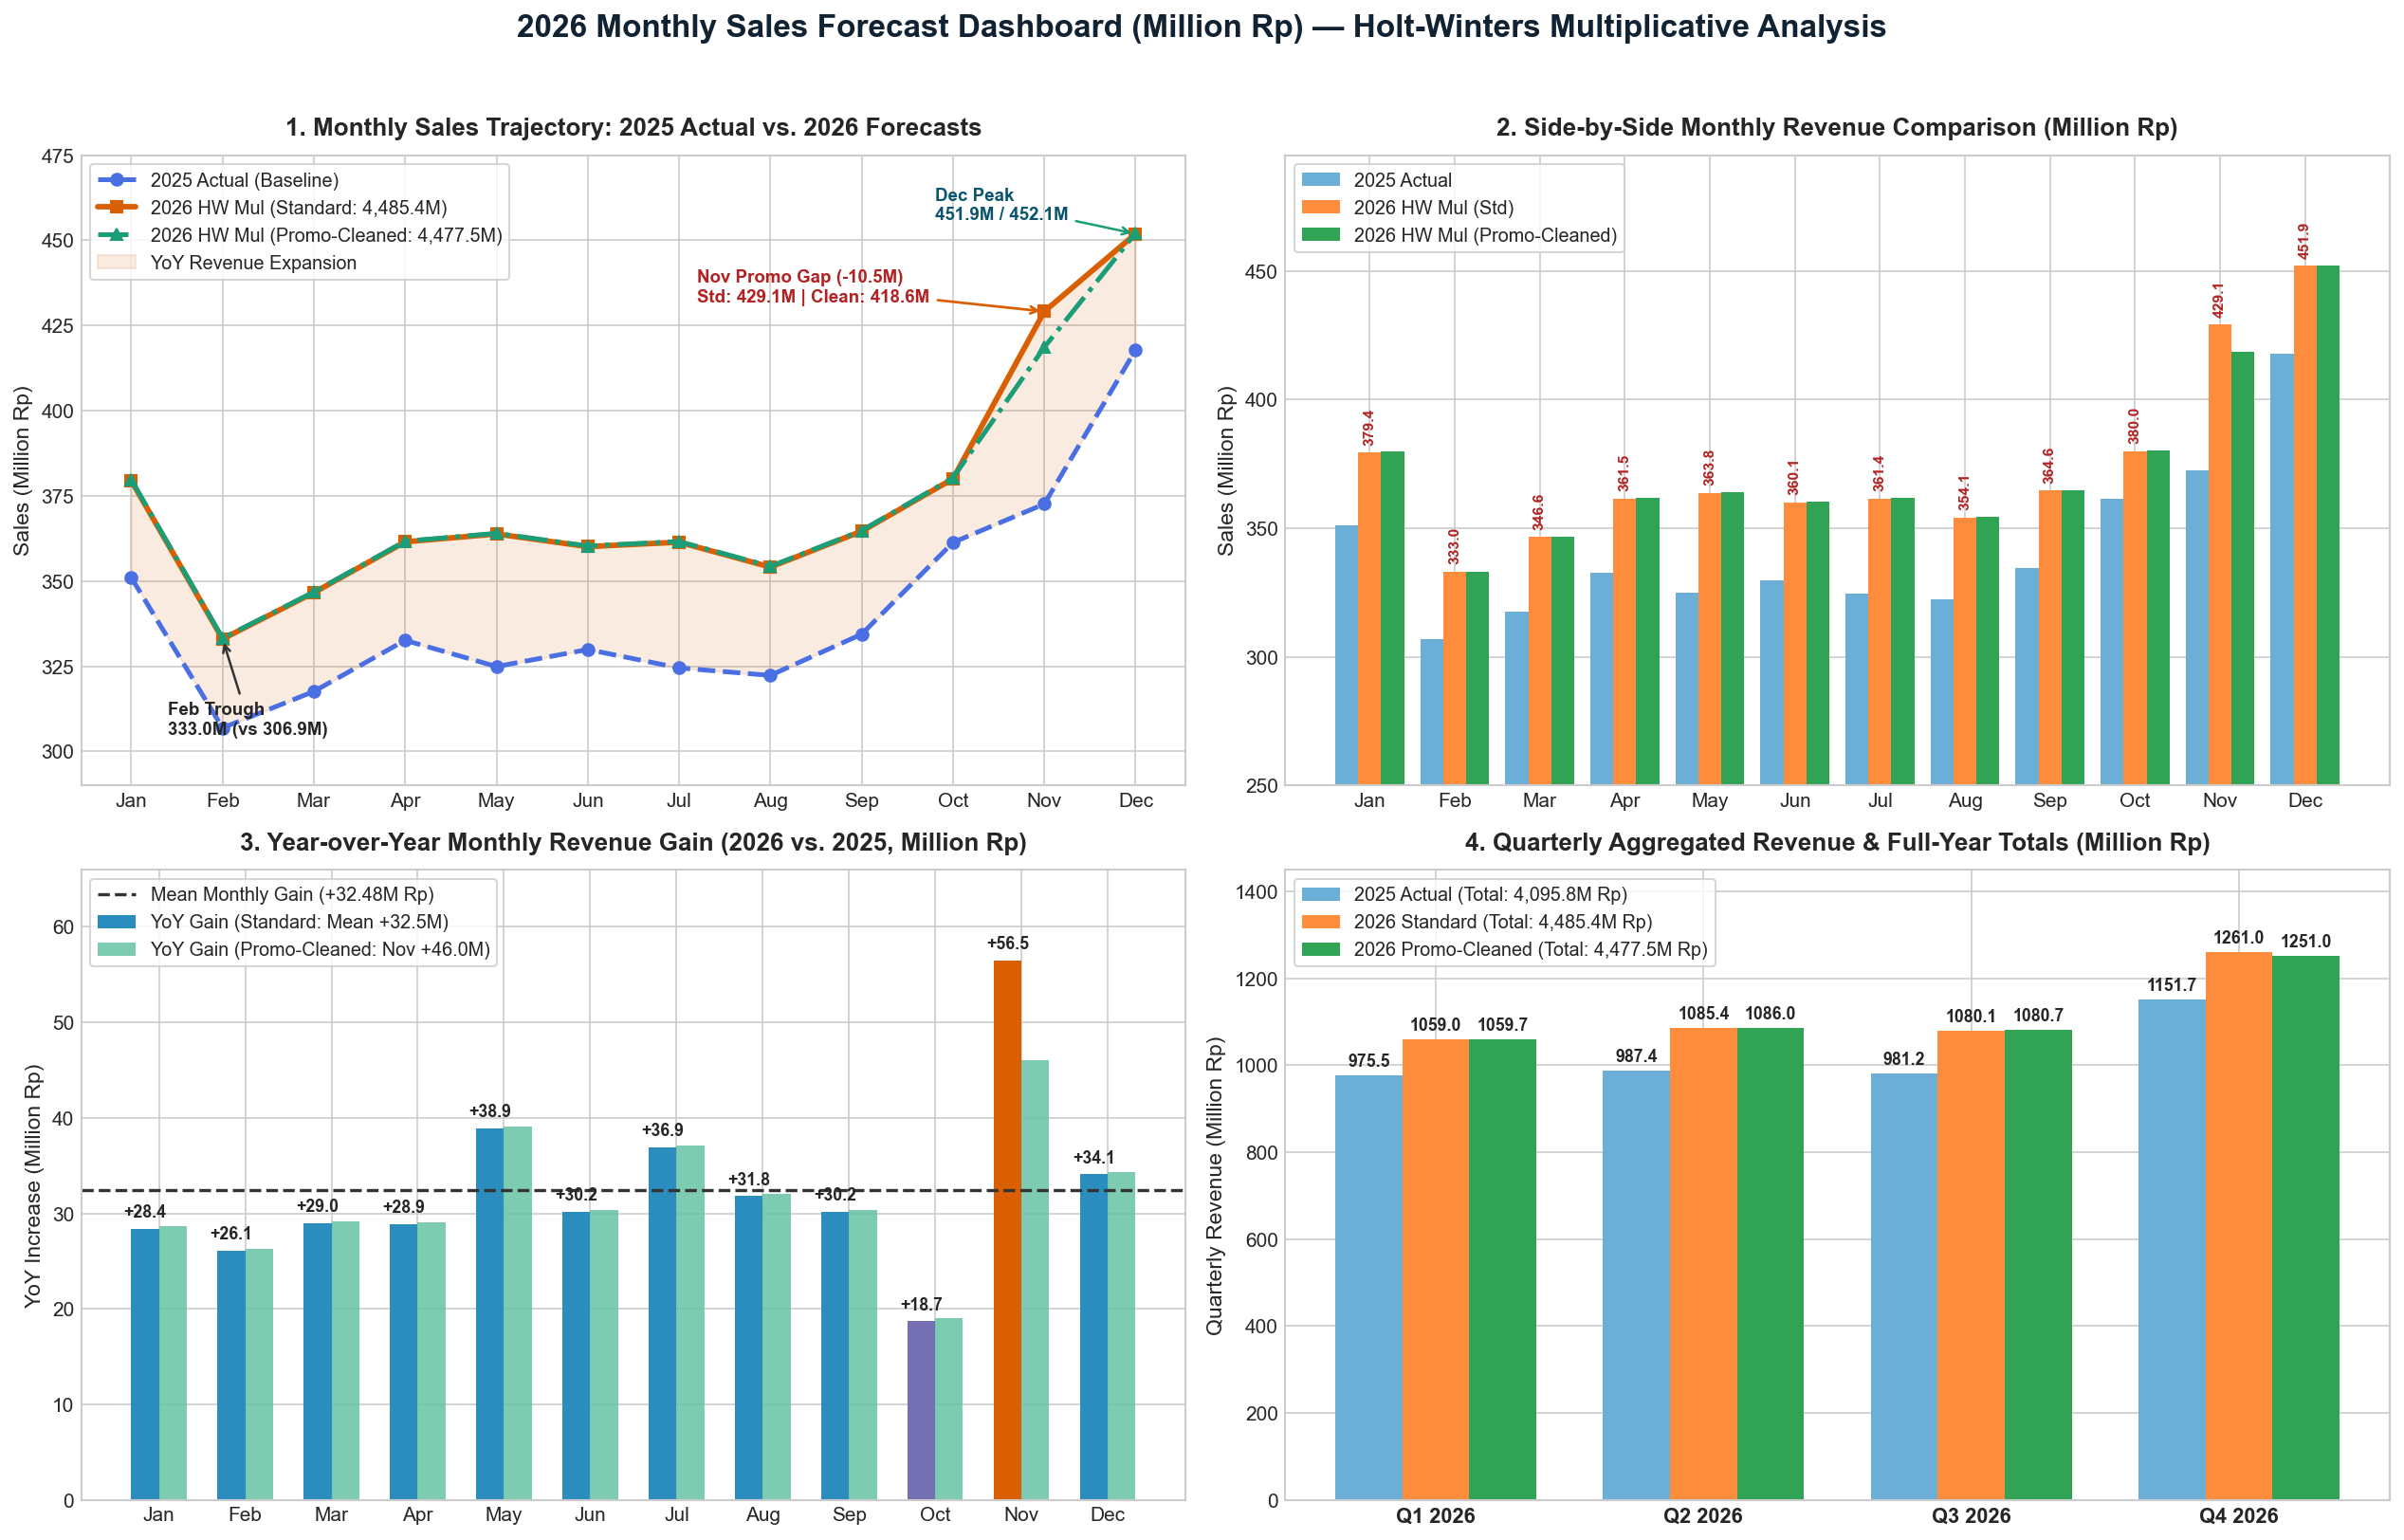

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. LOAD THE 2026 FORECAST TABLE DATA
# ------------------------------------------------------------------------------
data = {
    "Month": [
        "Jan 2026", "Feb 2026", "Mar 2026", "Apr 2026", "May 2026", "Jun 2026",
        "Jul 2026", "Aug 2026", "Sep 2026", "Oct 2026", "Nov 2026", "Dec 2026"
    ],
    "Month_Short": ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    "2025_Actual": [351.0, 306.9, 317.6, 332.6, 324.9, 329.9, 324.5, 322.3, 334.4, 361.3, 372.6, 417.8],
    "2026_HW_Mul_Std": [379.4, 333.0, 346.6, 361.5, 363.8, 360.1, 361.4, 354.1, 364.6, 380.0, 429.1, 451.9],
    "2026_HW_Mul_PromoCleaned": [379.7, 333.2, 346.8, 361.7, 364.0, 360.3, 361.6, 354.3, 364.8, 380.3, 418.6, 452.1],
    "YoY_Diff_Std": [28.4, 26.1, 29.0, 28.9, 38.9, 30.2, 36.9, 31.8, 30.2, 18.7, 56.5, 34.1]
}

df_viz = pd.DataFrame(data)
df_viz["YoY_Diff_Cleaned"] = (df_viz["2026_HW_Mul_PromoCleaned"] - df_viz["2025_Actual"]).round(1)
df_viz["Quarter"] = ["Q1 2026"] * 3 + ["Q2 2026"] * 3 + ["Q3 2026"] * 3 + ["Q4 2026"] * 3

# ------------------------------------------------------------------------------
# 2. CREATE 4-PANEL EXECUTIVE FORECAST DASHBOARD
# ------------------------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(17, 11), dpi=150)
fig.suptitle(
    "2026 Monthly Sales Forecast Dashboard (Million Rp) — Holt-Winters Multiplicative Analysis",
    fontsize=16, fontweight="bold", y=0.98, color="#112233"
)

x = np.arange(len(df_viz))
months = df_viz["Month_Short"]

# --- Panel 1 (Top-Left): Monthly Sales Trajectory & Shaded Growth Lift ---
ax1 = axes[0, 0]
ax1.plot(x, df_viz["2025_Actual"], marker="o", lw=2.4, color="#4a6fe3", linestyle="--", label="2025 Actual (Baseline)")
ax1.plot(x, df_viz["2026_HW_Mul_Std"], marker="s", lw=2.8, color="#d95f02", label="2026 HW Mul (Standard: 4,485.4M)")
ax1.plot(x, df_viz["2026_HW_Mul_PromoCleaned"], marker="^", lw=2.4, color="#1b9e77", linestyle="-.", label="2026 HW Mul (Promo-Cleaned: 4,477.5M)")
ax1.fill_between(x, df_viz["2025_Actual"], df_viz["2026_HW_Mul_Std"], color="#d95f02", alpha=0.12, label="YoY Revenue Expansion")

ax1.annotate("Feb Trough\n333.0M (vs 306.9M)", xy=(1, 333.0), xytext=(0.4, 305),
             arrowprops=dict(arrowstyle="->", color="#333", lw=1.2), fontsize=9, fontweight="bold")
ax1.annotate("Nov Promo Gap (-10.5M)\nStd: 429.1M | Clean: 418.6M", xy=(10, 429.1), xytext=(6.2, 432),
             arrowprops=dict(arrowstyle="->", color="#d95f02", lw=1.3), fontsize=9, fontweight="bold", color="#b22222")
ax1.annotate("Dec Peak\n451.9M / 452.1M", xy=(11, 451.9), xytext=(8.8, 456),
             arrowprops=dict(arrowstyle="->", color="#1b9e77", lw=1.2), fontsize=9, fontweight="bold", color="#0b556c")

ax1.set_title("1. Monthly Sales Trajectory: 2025 Actual vs. 2026 Forecasts", fontsize=12.5, fontweight="bold", pad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(months, fontsize=10)
ax1.set_ylabel("Sales (Million Rp)", fontsize=11)
ax1.set_ylim(290, 475)
ax1.legend(loc="upper left", frameon=True, fontsize=9.5)

# --- Panel 2 (Top-Right): Side-by-Side Monthly Grouped Bar Chart ---
ax2 = axes[0, 1]
w = 0.27
b1 = ax2.bar(x - w, df_viz["2025_Actual"], width=w, color="#6baed6", label="2025 Actual")
b2 = ax2.bar(x, df_viz["2026_HW_Mul_Std"], width=w, color="#fd8d3c", label="2026 HW Mul (Std)")
b3 = ax2.bar(x + w, df_viz["2026_HW_Mul_PromoCleaned"], width=w, color="#31a354", label="2026 HW Mul (Promo-Cleaned)")

for bar in b2:
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3, f"{bar.get_height():.1f}",
             ha="center", va="bottom", fontsize=7.5, fontweight="bold", color="#b22222", rotation=90)

ax2.set_title("2. Side-by-Side Monthly Revenue Comparison (Million Rp)", fontsize=12.5, fontweight="bold", pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(months, fontsize=10)
ax2.set_ylabel("Sales (Million Rp)", fontsize=11)
ax2.set_ylim(250, 495)
ax2.legend(loc="upper left", frameon=True, fontsize=9.5)

# --- Panel 3 (Bottom-Left): Year-over-Year Monthly Revenue Gain ---
ax3 = axes[1, 0]
colors_yoy = [
    "#d95f02" if val == df_viz["YoY_Diff_Std"].max()
    else ("#7570b3" if val == df_viz["YoY_Diff_Std"].min() else "#2b8cbe")
    for val in df_viz["YoY_Diff_Std"]
]

bars_yoy = ax3.bar(x - 0.16, df_viz["YoY_Diff_Std"], width=0.32, color=colors_yoy, label="YoY Gain (Standard: Mean +32.5M)")
bars_yoy_clean = ax3.bar(x + 0.16, df_viz["YoY_Diff_Cleaned"], width=0.32, color="#66c2a4", alpha=0.85, label="YoY Gain (Promo-Cleaned: Nov +46.0M)")

mean_yoy = df_viz["YoY_Diff_Std"].mean()
ax3.axhline(mean_yoy, color="#333333", linestyle="--", lw=1.6, label=f"Mean Monthly Gain (+{mean_yoy:.2f}M Rp)")

for bar in bars_yoy:
    ax3.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f"+{bar.get_height():.1f}",
             ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax3.set_title("3. Year-over-Year Monthly Revenue Gain (2026 vs. 2025, Million Rp)", fontsize=12.5, fontweight="bold", pad=10)
ax3.set_xticks(x)
ax3.set_xticklabels(months, fontsize=10)
ax3.set_ylabel("YoY Increase (Million Rp)", fontsize=11)
ax3.set_ylim(0, 66)
ax3.legend(loc="upper left", frameon=True, fontsize=9.5)

# --- Panel 4 (Bottom-Right): Quarterly & Full-Year Revenue Totals ---
ax4 = axes[1, 1]
q_summary = df_viz.groupby("Quarter", sort=False)[["2025_Actual", "2026_HW_Mul_Std", "2026_HW_Mul_PromoCleaned"]].sum()

qx = np.arange(len(q_summary))
qw = 0.25
qb1 = ax4.bar(qx - qw, q_summary["2025_Actual"], width=qw, color="#6baed6", label="2025 Actual (Total: 4,095.8M Rp)")
qb2 = ax4.bar(qx, q_summary["2026_HW_Mul_Std"], width=qw, color="#fd8d3c", label="2026 Standard (Total: 4,485.4M Rp)")
qb3 = ax4.bar(qx + qw, q_summary["2026_HW_Mul_PromoCleaned"], width=qw, color="#31a354", label="2026 Promo-Cleaned (Total: 4,477.5M Rp)")

for bars in [qb1, qb2, qb3]:
    for bar in bars:
        ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 12, f"{bar.get_height():.1f}",
                 ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax4.set_title("4. Quarterly Aggregated Revenue & Full-Year Totals (Million Rp)", fontsize=12.5, fontweight="bold", pad=10)
ax4.set_xticks(qx)
ax4.set_xticklabels(q_summary.index, fontsize=10.5, fontweight="bold")
ax4.set_ylabel("Quarterly Revenue (Million Rp)", fontsize=11)
ax4.set_ylim(0, 1450)
ax4.legend(loc="upper left", frameon=True, fontsize=9.5)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("forecast_2026_dashboard.png", bbox_inches="tight")
plt.show()